In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
(x_train, _), (x_test, _) = tf.keras.datasets.mnist.load_data()

x_train = x_train / 255.0
x_test = x_test / 255.0

x_train = np.reshape(x_train, (len(x_train), 784))
x_test = np.reshape(x_test, (len(x_test), 784))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [ ]:
noise_factor = 0.3

x_train_noisy = x_train + noise_factor * np.random.normal(
    loc=0.0, scale=1.0, size=x_train.shape
)

x_test_noisy = x_test + noise_factor * np.random.normal(
    loc=0.0, scale=1.0, size=x_test.shape
)

x_train_noisy = np.clip(x_train_noisy, 0.0, 1.0)
x_test_noisy = np.clip(x_test_noisy, 0.0, 1.0)

In [ ]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),

    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),

    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(784, activation='sigmoid')
])

In [ ]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy'
)

In [ ]:
model.fit(
    x_train_noisy,
    x_train,
    epochs=5,
    batch_size=256,
    validation_data=(x_test_noisy, x_test)
)

Epoch 1/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - loss: 0.2357 - val_loss: 0.1615
Epoch 2/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - loss: 0.1452 - val_loss: 0.1318
Epoch 3/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 0.1275 - val_loss: 0.1211
Epoch 4/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - loss: 0.1191 - val_loss: 0.1146
Epoch 5/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.1138 - val_loss: 0.1103


In [ ]:
decoded_images = model.predict(x_test_noisy[:5])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step


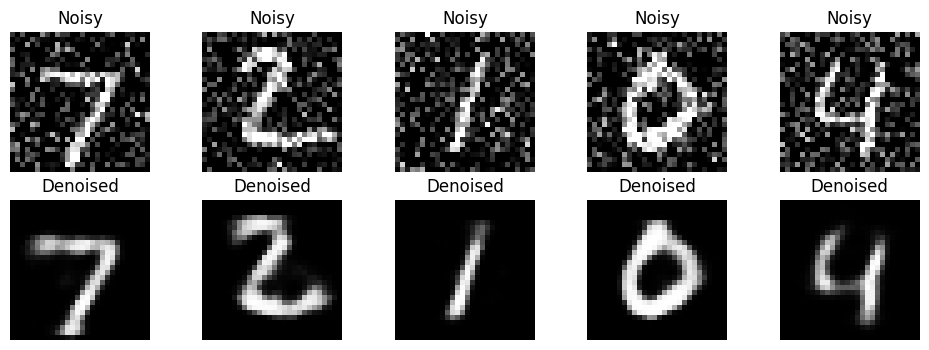

In [ ]:
plt.figure(figsize=(12, 4))

for i in range(5):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test_noisy[i].reshape(28, 28), cmap='gray')
    plt.title("Noisy")
    plt.axis('off')

    plt.subplot(2, 5, i + 6)
    plt.imshow(decoded_images[i].reshape(28, 28), cmap='gray')
    plt.title("Denoised")
    plt.axis('off')

plt.show()